In [8]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.metrics import mean_squared_error

In [11]:
insurance_data = pd.read_csv("Project_1/insurance.csv")
X = insurance_data.drop(columns = ["charges"])
y = insurance_data["charges"]

X = pd.get_dummies(X,columns=["region"],drop_first = False,dtype = int)


X["sex"] = X["sex"].map({"female":1,"male":0}) #Encoding categorical variable
X["smoker"] = X["smoker"].map({"yes":1,"no":0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

MSE for alpha = 0.001 is ---> 33596918.49260664
MSE for alpha = 0.1 is ---> 33597180.37548649
MSE for alpha = 2 is ---> 33615034.16817718
MSE for alpha = 5 is ---> 33641228.012641646
MSE for alpha = 10 is ---> 33681318.78237888
MSE for alpha = 20 is ---> 33764201.88887349
MSE for alpha = 30 is ---> 33851777.379185945
MSE for alpha = 40 is ---> 33904639.0554767
MSE for alpha = 50 is ---> 33950393.34079369
MSE for alpha = 70 is ---> 34049863.26624179
MSE for alpha = 80 is ---> 34103196.30499006
MSE for alpha = 100 is ---> 34215583.12377537


<Axes: >

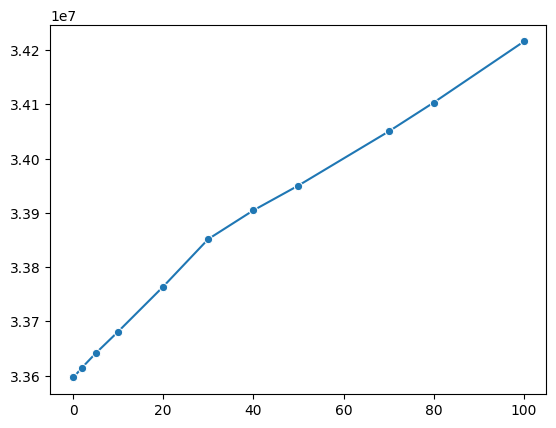

In [19]:
import seaborn as sns

alphas = [0.001,0.1,2,5,10,20,30,40,50,70,80,100]
mses = []
for a in alphas:
    model = Lasso(alpha = a)
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_pred,y_test)
    print(f"MSE for alpha = {a} is --->",mse)
    mses.append(mse)

sns.lineplot(x= alphas ,y= mses ,marker="o")

In [27]:
from sklearn.linear_model import LassoCV
a= [0.001,0.1,2,5,10,20,30,40,50,70,80,100]
lasso_cv_model =LassoCV(
     alphas = a,
     cv = 5,
     max_iter =1000,
     random_state =43
)
lasso_cv_model.fit(X_train, y_train)
print("best alpha --->" ,lasso_cv_model.alpha_)

y_pred = lasso_cv_model.predict(X_test)
mse = mean_squared_error(y_pred,y_test)
print(f"MSE for alpha ={lasso_cv_model.alpha_} is --->",mse)

best alpha ---> 80.0
MSE for alpha =80.0 is ---> 34103196.30499006
